# Consumer Complaint Classification: Fine-tuned DistilBERT
Run in its own session with a GPU and internet enabled.

## 1. Imports

In [34]:
import pandas as pd
import numpy as np
import torch
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer
from transformers import DataCollatorWithPadding


## 2. Load the data

In [17]:
df = pd.read_csv("/kaggle/input/datasets/shashwatwork/consume-complaints-dataset-fo-nlp/complaints_processed.csv")
df = df.drop(columns=["Unnamed: 0"])
df.columns = ["label", "text"]
df = df.dropna()
print(df.shape)

(162411, 2)


## 3. Balance the classes
12,000 rows per class.

In [18]:
df = df.groupby("label").sample(n=12000, random_state=42)
# shuffle the rows so the classes are mixed together
df = df.sample(frac=1, random_state=42).reset_index(drop=True)
print(df["label"].value_counts())

label
credit_reporting       12000
mortgages_and_loans    12000
credit_card            12000
retail_banking         12000
debt_collection        12000
Name: count, dtype: int64


## 4. Train, validation and test split

In [19]:
# split the data into 70% train, 15% validation, 15% test
train_df, temp_df = train_test_split(df, test_size=0.3, stratify=df["label"], random_state=42)
val_df, test_df = train_test_split(temp_df, test_size=0.5, stratify=temp_df["label"], random_state=42)
print(train_df.shape, val_df.shape, test_df.shape)

(42000, 2) (9000, 2) (9000, 2)


In [20]:
# turn the class names into numbers 0 to 4
encoder = LabelEncoder()
y_train = encoder.fit_transform(train_df["label"])
y_val = encoder.transform(val_df["label"])
y_test = encoder.transform(test_df["label"])
print(encoder.classes_)

['credit_card' 'credit_reporting' 'debt_collection' 'mortgages_and_loans'
 'retail_banking']


## 5. Tokenize

In [35]:
model_name = "distilbert-base-uncased"
hf_tokenizer = AutoTokenizer.from_pretrained(model_name)
train_enc = hf_tokenizer(list(train_df["text"]), truncation=True, max_length=256)
val_enc = hf_tokenizer(list(val_df["text"]), truncation=True, max_length=256)
test_enc = hf_tokenizer(list(test_df["text"]), truncation=True, max_length=256)
print(len(train_enc["input_ids"]))

42000


In [36]:
class ComplaintDataset(torch.utils.data.Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = {key: torch.tensor(val[idx]) for key, val in self.encodings.items()}
        item["labels"] = torch.tensor(int(self.labels[idx]))
        return item

train_ds = ComplaintDataset(train_enc, y_train)
val_ds = ComplaintDataset(val_enc, y_val)
test_ds = ComplaintDataset(test_enc, y_test)
print(len(train_ds), len(val_ds), len(test_ds))

42000 9000 9000


## 6. Fine-tune DistilBERT

In [37]:
data_collator = DataCollatorWithPadding(hf_tokenizer)
model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=5)
args = TrainingArguments(output_dir="results", num_train_epochs=3, per_device_train_batch_size=16, per_device_eval_batch_size=32, eval_strategy="epoch", save_strategy="no", fp16=True, report_to="none")
trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=val_ds, data_collator=data_collator)
trainer.train()
print("Training finished")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super(

Epoch,Training Loss,Validation Loss
1,0.937789,0.789791
2,0.691586,0.753226
3,0.477988,0.812754


Training finished


## 7. Evaluate on the test set

In [38]:
pred = trainer.predict(test_ds)
y_pred = np.argmax(pred.predictions, axis=1)
print(classification_report(y_test, y_pred, target_names=encoder.classes_))

                     precision    recall  f1-score   support

        credit_card       0.84      0.84      0.84      1800
   credit_reporting       0.84      0.85      0.85      1800
    debt_collection       0.85      0.83      0.84      1800
mortgages_and_loans       0.89      0.89      0.89      1800
     retail_banking       0.89      0.91      0.90      1800

           accuracy                           0.86      9000
          macro avg       0.86      0.86      0.86      9000
       weighted avg       0.86      0.86      0.86      9000



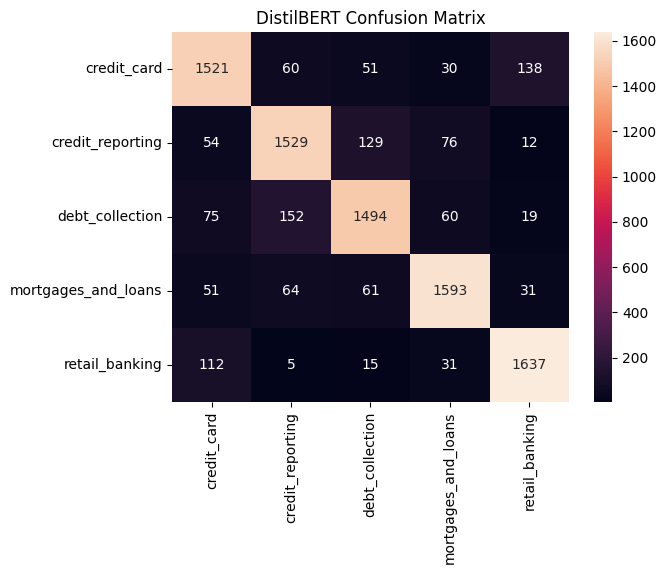

[[1521   60   51   30  138]
 [  54 1529  129   76   12]
 [  75  152 1494   60   19]
 [  51   64   61 1593   31]
 [ 112    5   15   31 1637]]


In [39]:
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", xticklabels=encoder.classes_, yticklabels=encoder.classes_)
plt.title("DistilBERT Confusion Matrix")
plt.show()
print(cm)

## 8. Compare all four models

In [40]:
results = {"SimpleRNN": [0.6908, 0.6915, 0.6908, 0.6753], "LSTM": [0.8258, 0.8257, 0.8258, 0.8254], "GRU": [0.8444, 0.8464, 0.8444, 0.8447]}
results["DistilBERT"] = [accuracy_score(y_test, y_pred), precision_score(y_test, y_pred, average="macro"), recall_score(y_test, y_pred, average="macro"), f1_score(y_test, y_pred, average="macro")]
table = pd.DataFrame(results, index=["Accuracy", "Precision", "Recall", "F1"]).T
print(table)

            Accuracy  Precision    Recall       F1
SimpleRNN   0.690800   0.691500  0.690800  0.67530
LSTM        0.825800   0.825700  0.825800  0.82540
GRU         0.844400   0.846400  0.844400  0.84470
DistilBERT  0.863778   0.863696  0.863778  0.86368


## 9. Save the model

In [41]:
trainer.save_model("complaint_model")
hf_tokenizer.save_pretrained("complaint_model")
print(list(encoder.classes_))

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

['credit_card', 'credit_reporting', 'debt_collection', 'mortgages_and_loans', 'retail_banking']


## 10. Gradio app

In [42]:
!pip install gradio
print("Installed")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 29.4 MB/s  0:00:00 eta 0:00:01
  Attempting uninstall: pillow
    Found existing installation: pillow 13.0.0
    Uninstalling pillow-13.0.0:
      Successfully uninstalled pillow-13.0.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.
Installed


In [43]:
import re
import gradio as gr
import torch.nn.functional as F

labels = list(encoder.classes_)
model.eval()

def predict(text):
    # the training text was lowercase without punctuation and numbers, so we clean the input the same way
    text = re.sub(r"[^a-z\s]", " ", text.lower())
    inputs = hf_tokenizer(text, return_tensors="pt", truncation=True, max_length=256).to(model.device)
    with torch.no_grad():
        logits = model(**inputs).logits
    probs = F.softmax(logits, dim=1)[0].cpu().numpy()
    return {labels[i]: float(probs[i]) for i in range(len(labels))}

demo = gr.Interface(fn=predict, inputs=gr.Textbox(lines=6, label="Complaint"), outputs=gr.Label(num_top_classes=5, label="Prediction"), title="Consumer Complaint Classifier")
demo.launch(share=True)
print("App is running")

* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://5a7f118567a0f12e1d.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


App is running
